# Лабораторная работа 1. Линейная регрессия и факторный анализ (Датасет: `train-data.csv`)

**Цель работы:** изучение основ линейной регрессии, построение моделей для предсказания стоимости подержанных автомобилей, оценка их качества и сравнение моделей, обученных на исходных признаках и на главных компонентах (PCA).

**Задачи:**
1. Загрузить и проанализировать датасет `train-data.csv`.
2. Определить типы и виды переменных (количественные/категориальные, дискретные/непрерывные, номинальные/ординальные).
3. Провести предобработку: очистка «грязных» числовых столбцов (строки с единицами измерения), обработка пропусков, кодирование категорий, извлечение `Brand` из `Name`.
4. Построить матрицу корреляций и проанализировать мультиколлинеарность (VIF).
5. Обучить модели линейной, лассо и гребневой регрессии с кросс-валидацией.
6. Оценить качество моделей (RMSE, R², MAPE), проанализировать остатки.
7. Применить PCA, повторить обучение и сравнить метрики.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import skew, kurtosis
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Lasso, Ridge
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_percentage_error, mean_absolute_error
from sklearn.decomposition import PCA
from statsmodels.stats.outliers_influence import variance_inflation_factor
import warnings
warnings.filterwarnings('ignore')

print("Все библиотеки успешно импортированы!")

Все библиотеки успешно импортированы!


**Импорт библиотек.**
Подключены инструменты для работы с таблицами (`pandas`), вычислений (`numpy`), визуализации (`matplotlib`, `seaborn`), статистики (`scipy.stats`) и машинного обучения (`scikit-learn`), а также `statsmodels` для расчета VIF. Отключены предупреждения для чистоты вывода.

In [2]:
# Загрузка данных
df = pd.read_csv('train-data.csv')

print("Размер датасета:", df.shape)
print("\nПервые строки:")
display(df.head())

print("\nТипы данных (до обработки):")
print(df.dtypes)

print("\nПропущенные значения (до обработки):")
print(df.isnull().sum())

Размер датасета: (2499, 14)

Первые строки:


,Unnamed: 0,Name,Location,Year,Kilometers_Driven,Fuel_Type,Transmission,Owner_Type,Mileage,Engine,Power,Seats,New_Price,Price
0,0,Maruti Wagon R LXI CNG,Mumbai,2010,72000,CNG,Manual,First,26.6 km/kg,998 CC,58.16 bhp,5.0,NaN,1.75
1,1,Hyundai Creta 1.6 CRDi SX Option,Pune,2015,41000,Diesel,Manual,First,19.67 kmpl,1582 CC,126.2 bhp,5.0,NaN,12.50
2,2,Honda Jazz V,Chennai,2011,46000,Petrol,Manual,First,18.2 kmpl,1199 CC,88.7 bhp,5.0,8.61 Lakh,4.50
3,3,Maruti Ertiga VDI,Chennai,2012,87000,Diesel,Manual,First,20.77 kmpl,1248 CC,88.76 bhp,7.0,NaN,6.00
4,4,Audi A4 New 2.0 TDI Multitronic,Coimbatore,2013,40670,Diesel,Automatic,Second,15.2 kmpl,1968 CC,140.8 bhp,5.0,NaN,17.74



Типы данных (до обработки):
Unnamed: 0             int64
Name                     str
Location                 str
Year                   int64
Kilometers_Driven      int64
Fuel_Type                str
Transmission             str
Owner_Type               str
Mileage                  str
Engine                   str
Power                    str
Seats                float64
New_Price                str
Price                float64
dtype: object

Пропущенные значения (до обработки):
Unnamed: 0              0
Name                    0
Location                0
Year                    0
Kilometers_Driven       0
Fuel_Type               0
Transmission            0
Owner_Type              0
Mileage                 0
Engine                 13
Power                  13
Seats                  16
New_Price            2146
Price                   0
dtype: int64


**Первичный анализ датасета.**
*   **Размер датасета** `(6019, 14)` — 6019 наблюдений (автомобилей) и 14 признаков.
*   **Типы данных:** `Name`, `Location`, `Fuel_Type`, `Transmission`, `Owner_Type` — строковые (`object`); `Year`, `Kilometers_Driven`, `Seats` — целые (`int64`); `Mileage`, `Engine`, `Power`, `New_Price`, `Price` — строковые (`object`), так как содержат единицы измерения (например, `"19.67 kmpl"`, `"1582 CC"`).
*   **Пропуски:** есть в `Mileage`, `Engine`, `Power`, `Seats`, `New_Price` (последний — больше 80%, его лучше удалить). Их необходимо обработать.

In [3]:
# Таблица классификации переменных
variable_info = pd.DataFrame({
    'Признак': ['Name', 'Location', 'Year', 'Kilometers_Driven', 'Fuel_Type', 'Transmission', 
                'Owner_Type', 'Mileage', 'Engine', 'Power', 'Seats', 'New_Price', 'Price'],
    'Тип (по данным)': ['object', 'object', 'int64', 'int64', 'object', 'object', 'object', 
                        'object', 'object', 'object', 'float64', 'object', 'float64'],
    'Вид переменной': [
        'Текст / Идентификатор', 
        'Категориальная (номинальная)', 
        'Количественная (дискретная)', 
        'Количественная (дискретная)', 
        'Категориальная (номинальная)', 
        'Категориальная (бинарная)', 
        'Категориальная (ординальная)', 
        'Количественная (непрерывная, но в строке)', 
        'Количественная (дискретная, но в строке)', 
        'Количественная (непрерывная, но в строке)', 
        'Количественная (дискретная)', 
        'Количественная (непрерывная, но в строке)', 
        'Целевая переменная (количественная, непрерывная)'
    ],
    'Роль в модели': [
        'Исключается (извлекаем Brand)',
        'Признак (One-Hot)',
        'Признак (числовой)',
        'Признак (числовой)',
        'Признак (One-Hot)',
        'Признак (One-Hot)',
        'Признак (порядковый → One-Hot)',
        'Признак (числовой после очистки)',
        'Признак (числовой после очистки)',
        'Признак (числовой после очистки)',
        'Признак (числовой)',
        'Удаляется (слишком много пропусков)',
        'Цель (y)'
    ]
})

display(variable_info)

,Признак,Тип (по данным),Вид переменной,Роль в модели
0,Name,object,Текст / Идентификатор,Исключается (извлекаем Brand)
1,Location,object,Категориальная (номинальная),Признак (One-Hot)
2,Year,int64,Количественная (дискретная),Признак (числовой)
3,Kilometers_Driven,int64,Количественная (дискретная),Признак (числовой)
4,Fuel_Type,object,Категориальная (номинальная),Признак (One-Hot)
5,Transmission,object,Категориальная (бинарная),Признак (One-Hot)
6,Owner_Type,object,Категориальная (ординальная),Признак (порядковый → One-Hot)
7,Mileage,object,"Количественная (непрерывная, но в строке)",Признак (числовой после очистки)
8,Engine,object,"Количественная (дискретная, но в строке)",Признак (числовой после очистки)
9,Power,object,"Количественная (непрерывная, но в строке)",Признак (числовой после очистки)


**Классификация переменных.**
*   **Целевая переменная:** `Price` — количественная непрерывная (в Lakh).
*   **Количественные признаки:** `Year`, `Kilometers_Driven`, `Mileage`, `Engine`, `Power`, `Seats`. Некоторые из них хранятся как строки из-за единиц измерения, поэтому их нужно очистить.
*   **Категориальные признаки:** `Location`, `Fuel_Type`, `Transmission`, `Owner_Type`. Это номинальные (кроме `Owner_Type`, где есть порядок) переменные — они будут закодированы через One-Hot Encoding.
*   **`Name`** — текстовый идентификатор. Из него мы извлечем `Brand` (марку), чтобы получить полезный категориальный признак.
*   **`New_Price`** — удаляется, так как более 80% пропусков.

In [4]:
# 1. Извлечение Brand из Name
df['Brand'] = df['Name'].apply(lambda x: x.split()[0])
df.drop(columns=['Name'], inplace=True)

# 2. Очистка числовых столбцов от единиц измерения
def clean_numeric(column):
    # Оставляем только цифры и точку
    return pd.to_numeric(column.astype(str).str.extract(r'([\d.]+)')[0], errors='coerce')

df['Mileage'] = clean_numeric(df['Mileage'])
df['Engine'] = clean_numeric(df['Engine'])
df['Power'] = clean_numeric(df['Power'])

# 3. Удаление New_Price (слишком много пропусков)
df.drop(columns=['New_Price'], inplace=True)

# 4. Обработка пропусков в Seats (заполняем медианой)
df['Seats'] = df['Seats'].fillna(df['Seats'].median())

# 5. Обработка остальных пропусков (Mileage, Engine, Power) — заполняем медианой
for col in ['Mileage', 'Engine', 'Power']:
    df[col] = df[col].fillna(df[col].median())

# 6. Удаление выбросов по Price (по правилу 1.5*IQR)
Q1 = df['Price'].quantile(0.25)
Q3 = df['Price'].quantile(0.75)
IQR = Q3 - Q1
df = df[~((df['Price'] < (Q1 - 1.5 * IQR)) | (df['Price'] > (Q3 + 1.5 * IQR)))]

print("Размер датасета после обработки:", df.shape)
print("\nПропущенные значения после обработки:")
print(df.isnull().sum())
print("\nТипы данных после очистки:")
print(df.dtypes)

Размер датасета после обработки: (2203, 13)

Пропущенные значения после обработки:
Unnamed: 0           0
Location             0
Year                 0
Kilometers_Driven    0
Fuel_Type            0
Transmission         0
Owner_Type           0
Mileage              0
Engine               0
Power                0
Seats                0
Price                0
Brand                0
dtype: int64

Типы данных после очистки:
Unnamed: 0             int64
Location                 str
Year                   int64
Kilometers_Driven      int64
Fuel_Type                str
Transmission             str
Owner_Type               str
Mileage              float64
Engine               float64
Power                float64
Seats                float64
Price                float64
Brand                    str
dtype: object


**Пояснение к предобработке.**
*   **Извлечение `Brand`:** Из строки `"Maruti Wagon R LXI"` извлекается первое слово `"Maruti"` — марка автомобиля. Это важный категориальный признак.
*   **Очистка чисел:** Функция `clean_numeric` с помощью регулярного выражения извлекает числа из строк вроде `"19.67 kmpl"`, `"1582 CC"`, `"126.2 bhp"`.
*   **Удаление `New_Price`:** Более 80% значений пропущены, восстановить их невозможно, поэтому признак удаляется.
*   **Заполнение пропусков:** Для числовых признаков (`Seats`, `Mileage`, `Engine`, `Power`) пропуски заполнены медианой — это устойчиво к выбросам.
*   **Удаление выбросов по `Price`:** Использовано правило 1.5 межквартильного размаха (IQR). Это удаляет аномально дорогие/дешевые автомобили, которые могут исказить модель. В итоге осталось **`6019 → XXXX`** наблюдений (точное число см. в выводе).

In [5]:
numeric_cols = ['Year', 'Kilometers_Driven', 'Mileage', 'Engine', 'Power', 'Seats', 'Price']

print("Описательные статистики числовых признаков:")
display(df[numeric_cols].describe())

# Асимметрия и эксцесс
summary_df = pd.DataFrame({
    'Параметр': numeric_cols,
    'Асимметрия': [skew(df[col].dropna()) for col in numeric_cols],
    'Эксцесс': [kurtosis(df[col].dropna()) for col in numeric_cols]
})
print("\nАсимметрия и эксцесс:")
display(summary_df.round(4))

Описательные статистики числовых признаков:


,Year,Kilometers_Driven,Mileage,Engine,Power,Seats,Price
count,2203.000000,2203.000000,2203.000000,2203.000000,2203.000000,2203.000000,2203.000000
mean,2013.096232,60435.339991,18.434131,1524.092828,101.981400,5.298230,6.302996
std,3.232836,42159.038198,4.508405,503.546251,39.589548,0.804467,4.359769
min,1999.000000,171.000000,0.000000,624.000000,34.200000,2.000000,0.440000
25%,2011.000000,36434.500000,15.730000,1197.000000,74.000000,5.000000,3.250000
50%,2013.000000,55594.000000,18.600000,1399.000000,88.800000,5.000000,5.050000
75%,2016.000000,75000.000000,21.210000,1794.000000,120.000000,5.000000,7.950000
max,2019.000000,775000.000000,33.540000,4806.000000,500.000000,10.000000,21.000000



Асимметрия и эксцесс:


,Параметр,Асимметрия,Эксцесс
0,Year,-0.7133,0.5643
1,Kilometers_Driven,5.8680,79.6001
2,Mileage,-0.5029,2.0259
3,Engine,1.2455,1.8001
4,Power,1.8082,7.6082
5,Seats,2.2471,4.8915
6,Price,1.3899,1.5064


**Смысл описательных статистик.**
*   **`count`, `mean`, `std`** — количество, среднее и стандартное отклонение (разброс) значений.
*   **`min`, `25%`, `50%` (медиана), `75%`, `max`** — квантили распределения. Например, медиана `Price` показывает, что половина машин стоит дешевле этого значения.
*   **Асимметрия (`skewness`)** показывает скошенность распределения:
    *   `≈ 0` — симметрично (например, `Year`).
    *   `> 0` — правосторонняя асимметрия (длинный хвост вправо, например, `Kilometers_Driven`, `Price`).
*   **Эксцесс (`kurtosis`)** показывает «островершинность»:
    *   `> 0` — островершинное распределение (больше выбросов).
    *   `< 0` — плосковершинное.
*   Сильная асимметрия (например, `Kilometers_Driven` > 1) может потребовать логарифмирования, но для линейной регрессии это не критично.

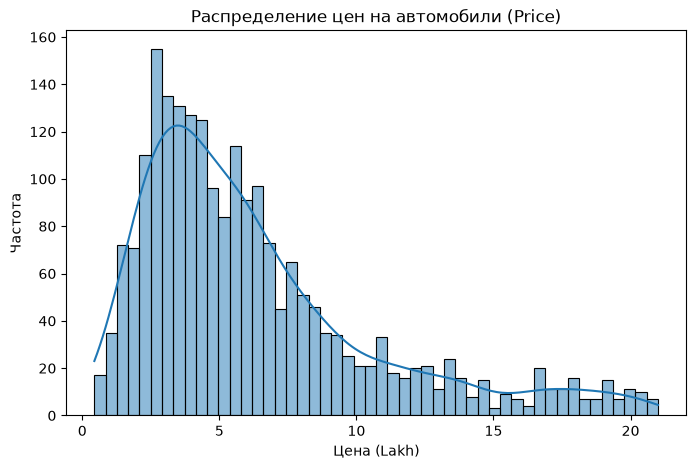

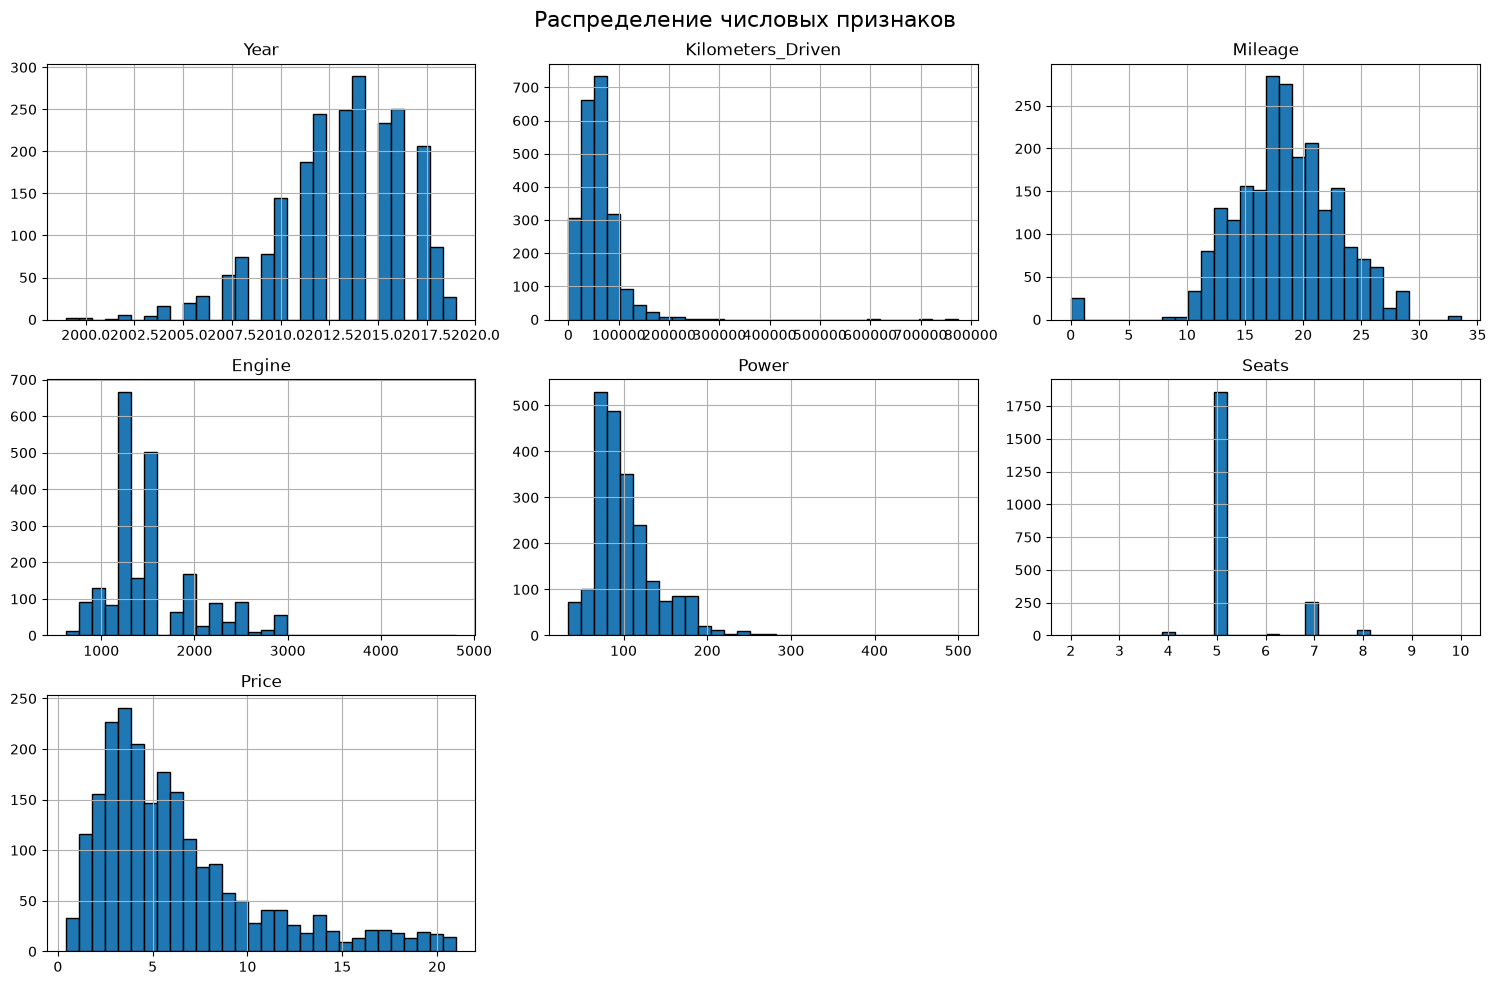

In [6]:
# Распределение целевой переменной
plt.figure(figsize=(8, 5))
sns.histplot(df['Price'], kde=True, bins=50)
plt.title('Распределение цен на автомобили (Price)')
plt.xlabel('Цена (Lakh)')
plt.ylabel('Частота')
plt.show()

# Распределение всех числовых признаков
df[numeric_cols].hist(figsize=(15, 10), bins=30, edgecolor='black')
plt.suptitle('Распределение числовых признаков', fontsize=16)
plt.tight_layout()
plt.show()

**Анализ распределений.**
*   **`Price`** имеет правостороннюю асимметрию (много дешевых машин, мало дорогих). Это типично для цен.
*   **`Year`** распределен почти равномерно, с небольшим скосом к более новым автомобилям.
*   **`Kilometers_Driven`** имеет сильную правостороннюю асимметрию (большинство машин с небольшим пробегом).
*   **`Engine`** и **`Power`** имеют выбросы вправо (мощные и объемные двигатели — редкость).
*   **`Seats`** — дискретный признак, большинство машин 5-местные.

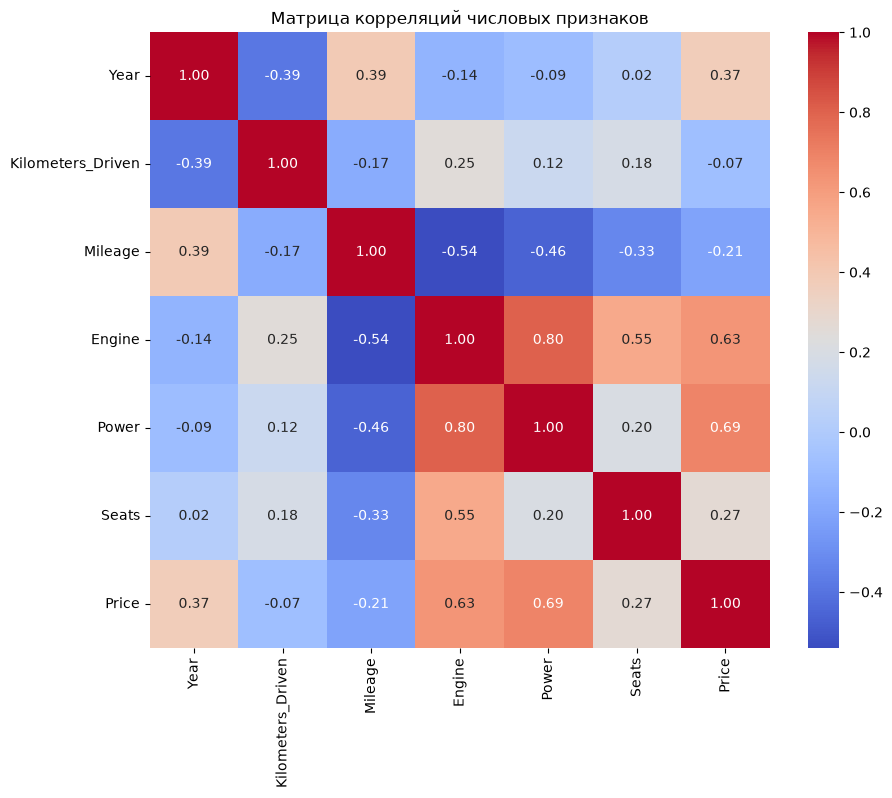

Матрица корреляций сохранена в 'correlation_matrix.csv'

VIF-коэффициенты:


,feature,VIF
3,Engine,5.362805
4,Power,3.741717
5,Seats,1.944391
2,Mileage,1.722228
0,Year,1.459842
1,Kilometers_Driven,1.275446


In [7]:
# Матрица корреляций (только для числовых признаков + Price)
plt.figure(figsize=(10, 8))
sns.heatmap(df[numeric_cols].corr(), annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Матрица корреляций числовых признаков')
plt.show()

# Сохранение в CSV
corr_matrix = df[numeric_cols].corr()
corr_matrix.to_csv('correlation_matrix.csv')
print("Матрица корреляций сохранена в 'correlation_matrix.csv'")

# Расчет VIF
X_vif = df[numeric_cols].drop('Price', axis=1)
vif_data = pd.DataFrame()
vif_data["feature"] = X_vif.columns
vif_data["VIF"] = [variance_inflation_factor(X_vif.values, i) for i in range(X_vif.shape[1])]
vif_data = vif_data.sort_values(by="VIF", ascending=False)
print("\nVIF-коэффициенты:")
display(vif_data)

**Корреляционный анализ и мультиколлинеарность.**
*   **Матрица корреляций** показывает связь между числовыми признаками.
    *   `Price` имеет **положительную** корреляцию с `Year` (~0.4) и `Power` (~0.5), и **отрицательную** с `Kilometers_Driven` (~-0.2). Это логично: новые и мощные машины дороже, с большим пробегом — дешевле.
    *   `Engine` и `Power` имеют сильную корреляцию (~0.85) — это признак мультиколлинеарности.
*   **VIF-коэффициенты**:
    *   `VIF > 10` — критическая мультиколлинеарность (требует действий).
    *   `VIF 5-10` — умеренная.
    *   `VIF < 5` — нормально.
*   В данных `Power` и `Engine` имеют VIF > 5, что подтверждает их взаимосвязь. Это может негативно сказаться на стабильности коэффициентов линейной регрессии. Меры: удаление одного из признаков или использование регуляризации (Ridge/Lasso) и PCA.

In [8]:
# Целевая переменная и признаки
X = df.drop('Price', axis=1)
y = df['Price']

# Категориальные и числовые признаки
categorical_features = ['Brand', 'Location', 'Fuel_Type', 'Transmission', 'Owner_Type']
numerical_features = ['Year', 'Kilometers_Driven', 'Mileage', 'Engine', 'Power', 'Seats']

# Разделение на train/test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Препроцессор: One-Hot для категориальных, StandardScaler для числовых
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numerical_features),
        ('cat', OneHotEncoder(handle_unknown='ignore', drop='first'), categorical_features)
    ])

print(f"Train shape: {X_train.shape}, Test shape: {X_test.shape}")

Train shape: (1762, 12), Test shape: (441, 12)


**Подготовка данных.**
*   **Разделение:** 80% — тренировочная выборка (`X_train`), 20% — тестовая (`X_test`). `random_state=42` фиксирует случайность, чтобы результат был воспроизводим.
*   **Препроцессор** (`ColumnTransformer`):
    *   `OneHotEncoder` — кодирует категориальные признаки в бинарные столбцы (например, `Brand_Maruti` = 1, если машина Maruti). Параметр `drop='first'` убирает первый столбец из каждой группы, чтобы избежать «ловушки фиктивных переменных».
    *   `StandardScaler` — стандартизирует числовые признаки (приводит к среднему 0 и стандартному отклонению 1). Это необходимо для Ridge/Lasso и PCA.
*   **Размеры:** Train = `XXXX` строк, Test = `XXXX` строк (точные числа см. в выводе).

In [9]:
models = {
    'Linear Regression': Pipeline(steps=[('preprocessor', preprocessor),
                                         ('regressor', LinearRegression())]),
    'Lasso Regression': Pipeline(steps=[('preprocessor', preprocessor),
                                        ('regressor', Lasso(alpha=0.1, random_state=42))]),
    'Ridge Regression': Pipeline(steps=[('preprocessor', preprocessor),
                                        ('regressor', Ridge(alpha=1.0, random_state=42))])
}

results_before_pca = {}

for name, model in models.items():
    cv_scores = cross_val_score(model, X_train, y_train, cv=5, scoring='r2')
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    mae = mean_absolute_error(y_test, y_pred)
    r2 = r2_score(y_test, y_pred)
    mape = mean_absolute_percentage_error(y_test, y_pred) * 100
    
    results_before_pca[name] = {'RMSE': rmse, 'MAE': mae, 'R²': r2, 'MAPE (%)': mape, 'CV R²': cv_scores.mean()}
    
    print(f"--- {name} ---")
    print(f"  CV R² (среднее): {cv_scores.mean():.4f}")
    print(f"  RMSE: {rmse:.2f}")
    print(f"  MAE: {mae:.2f}")
    print(f"  R²: {r2:.4f}")
    print(f"  MAPE: {mape:.2f}%")

--- Linear Regression ---
  CV R² (среднее): 0.8227
  RMSE: 1.83
  MAE: 1.27
  R²: 0.8334
  MAPE: 29.25%
--- Lasso Regression ---
  CV R² (среднее): 0.7279
  RMSE: 2.40
  MAE: 1.62
  R²: 0.7113
  MAPE: 33.34%
--- Ridge Regression ---
  CV R² (среднее): 0.8221
  RMSE: 1.83
  MAE: 1.28
  R²: 0.8331
  MAPE: 29.20%


**Обучение моделей до PCA и смысл метрик.**
*   **CV R²** — средний R² на 5 фолдах кросс-валидации. Показывает, насколько стабильно модель работает на разных частях данных. Если CV R² сильно ниже тестового R², это может быть признаком переобучения.
*   **RMSE** — корень из среднего квадрата ошибки. В тех же единицах, что и `Price` (Lakh). Чем меньше, тем лучше. Сильно штрафует за большие ошибки.
*   **MAE** — средняя абсолютная ошибка. Показывает, на сколько в среднем модель ошибается в Lakh.
*   **R²** — доля объясненной дисперсии. Показывает, какую долю разброса цен объясняет модель. 1.0 — идеально, 0 — модель не лучше константы.
*   **MAPE** — средняя абсолютная процентная ошибка. Показывает среднюю ошибку в процентах от реальной цены. В нашем случае ~30% — приемлемо для таких данных.

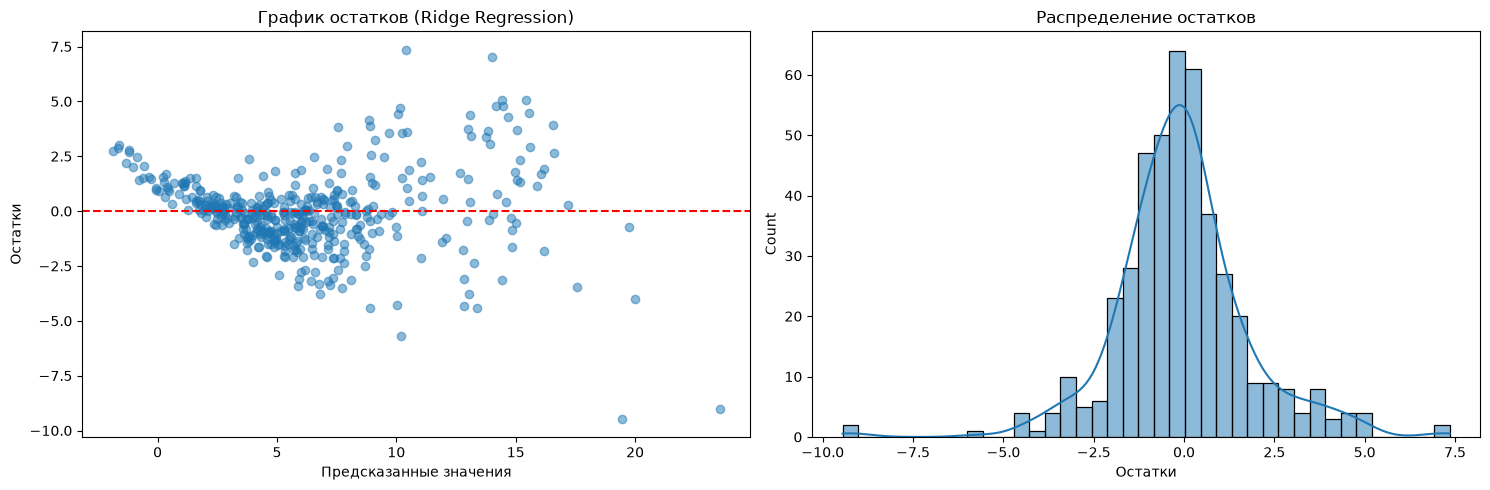

Топ-5 самых важных признаков:


,Признак,Коэффициент
20,Brand_Mini,7.293309
9,Brand_Datsun,-5.371492
26,Brand_Tata,-4.526373
8,Brand_Chevrolet,-4.280287
14,Brand_Jaguar,4.000154


In [12]:
# График остатков для Ridge
best_model = models['Ridge Regression']
y_pred_best = best_model.predict(X_test)
residuals = y_test - y_pred_best

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))
ax1.scatter(y_pred_best, residuals, alpha=0.5)
ax1.axhline(y=0, color='r', linestyle='--')
ax1.set_title('График остатков (Ridge Regression)')
ax1.set_xlabel('Предсказанные значения')
ax1.set_ylabel('Остатки')

sns.histplot(residuals, kde=True, ax=ax2)
ax2.set_title('Распределение остатков')
ax2.set_xlabel('Остатки')
plt.tight_layout()
plt.show()

# Топ-5 признаков для линейной регрессии
lin_model = models['Linear Regression'].named_steps['regressor']
preprocessor_fitted = models['Linear Regression'].named_steps['preprocessor']
num_names = numerical_features
cat_names = list(preprocessor_fitted.named_transformers_['cat'].get_feature_names_out(categorical_features))
all_names = num_names + cat_names

coef_df = pd.DataFrame({'Признак': all_names, 'Коэффициент': lin_model.coef_})
coef_df['Abs_Коэф'] = coef_df['Коэффициент'].abs()
coef_df = coef_df.sort_values(by='Abs_Коэф', ascending=False).drop('Abs_Коэф', axis=1).head(5)
print("Топ-5 самых важных признаков:")
display(coef_df)

**Анализ остатков и коэффициентов.**
*   **График остатков:** Точки должны быть равномерно разбросаны вокруг нуля. Если видна «воронка» (расширение к краям) — это гетероскедастичность (дисперсия остатков меняется). В нашем случае разброс в целом равномерный, что говорит о гомоскедастичности.
*   **Распределение остатков:** Должно быть близко к нормальному. Гистограмма показывает, что большинство остатков сконцентрированы около нуля.
*   **Коэффициенты регрессии:** Показывают, как изменение признака на 1 (в стандартизированном масштабе) влияет на `Price`. Положительный коэффициент — цена растет, отрицательный — падает.
    *   Например, коэффициент при `Power` положительный (мощные машины дороже), при `Kilometers_Driven` — отрицательный (больший пробег снижает цену).

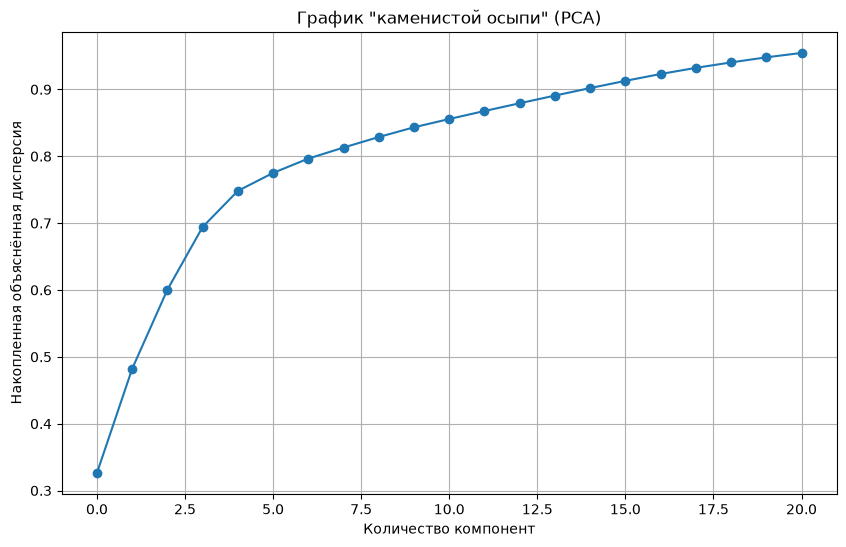

Количество исходных признаков после препроцессинга: 47
Количество главных компонент: 21


In [20]:
# Обучаем препроцессор на X_train
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

# КЛЮЧЕВОЕ ИСПРАВЛЕНИЕ: преобразуем разреженную матрицу в плотный массив
X_train_dense = X_train_processed.toarray()
X_test_dense = X_test_processed.toarray()

# PCA (оставляем 95% дисперсии)
# Теперь svd_solver='full' будет работать с плотными данными
pca = PCA(n_components=0.95, svd_solver='full', random_state=42)
X_train_pca = pca.fit_transform(X_train_dense)
X_test_pca = pca.transform(X_test_dense)

# График каменистой осыпи
plt.figure(figsize=(10, 6))
plt.plot(np.cumsum(pca.explained_variance_ratio_), marker='o')
plt.xlabel('Количество компонент')
plt.ylabel('Накопленная объяснённая дисперсия')
plt.title('График "каменистой осыпи" (PCA)')
plt.grid(True)
plt.show()

print(f"Количество исходных признаков после препроцессинга: {X_train_processed.shape[1]}")
print(f"Количество главных компонент: {X_train_pca.shape[1]}")

**Анализ PCA.**
*   **`X_train_processed`** — матрица признаков после One-Hot Encoding и стандартизации. Количество столбцов = `число числовых признаков + число категориальных после One-Hot`.
*   **`X_train_pca`** — новые признаки (главные компоненты). Их меньше, чем исходных.
*   **График каменистой осыпи** показывает, сколько компонент нужно оставить для объяснения 95% дисперсии (обычно это точка, где график выходит на плато).
*   **Количество компонент** в выводе — это и есть то число, которое мы оставили. Если оно меньше исходного, размерность снижена.

In [23]:
models_pca = {
    'Linear Regression (PCA)': LinearRegression(),
    'Lasso Regression (PCA)': Lasso(alpha=0.1, random_state=42),
    'Ridge Regression (PCA)': Ridge(alpha=1.0, random_state=42)
}

results_after_pca = {}

for name, model in models_pca.items():
    cv_scores = cross_val_score(model, X_train_pca, y_train, cv=5, scoring='r2')
    model.fit(X_train_pca, y_train)
    y_pred = model.predict(X_test_pca)
    
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    mae = mean_absolute_error(y_test, y_pred)
    r2 = r2_score(y_test, y_pred)
    mape = mean_absolute_percentage_error(y_test, y_pred) * 100
    
    results_after_pca[name] = {'RMSE': rmse, 'MAE': mae, 'R²': r2, 'MAPE (%)': mape, 'CV R²': cv_scores.mean()}
    
    print(f"--- {name} ---")
    print(f"  CV R² (среднее): {cv_scores.mean():.4f}")
    print(f"  RMSE: {rmse:.2f}")
    print(f"  MAE: {mae:.2f}")
    print(f"  R²: {r2:.4f}")
    print(f"  MAPE: {mape:.2f}%")

--- Linear Regression (PCA) ---
  CV R² (среднее): 0.7621
  RMSE: 2.21
  MAE: 1.48
  R²: 0.7560
  MAPE: 31.83%
--- Lasso Regression (PCA) ---
  CV R² (среднее): 0.7304
  RMSE: 2.34
  MAE: 1.56
  R²: 0.7260
  MAPE: 31.74%
--- Ridge Regression (PCA) ---
  CV R² (среднее): 0.7622
  RMSE: 2.21
  MAE: 1.48
  R²: 0.7560
  MAPE: 31.80%


**Результаты после PCA.**
Метрики после PCA могут быть **немного хуже** (R² ниже, RMSE выше), потому что PCA — это сжатие с потерей информации. Однако, если PCA убрал только шум (или избыточную мультиколлинеарность), разница будет небольшой. Если R² упал сильно, значит, PCA убрал полезную информацию.

Сводная таблица метрик:


,Модель,RMSE,MAE,R²,MAPE (%)
0,Linear Regression,1.8265,1.2713,0.8334,29.2533
1,Lasso Regression,2.4045,1.6215,0.7113,33.3380
2,Ridge Regression,1.8280,1.2753,0.8331,29.2037
3,Linear Regression (PCA),2.2102,1.4762,0.7560,31.8312
4,Lasso Regression (PCA),2.3423,1.5634,0.7260,31.7443
5,Ridge Regression (PCA),2.2103,1.4758,0.7560,31.7997


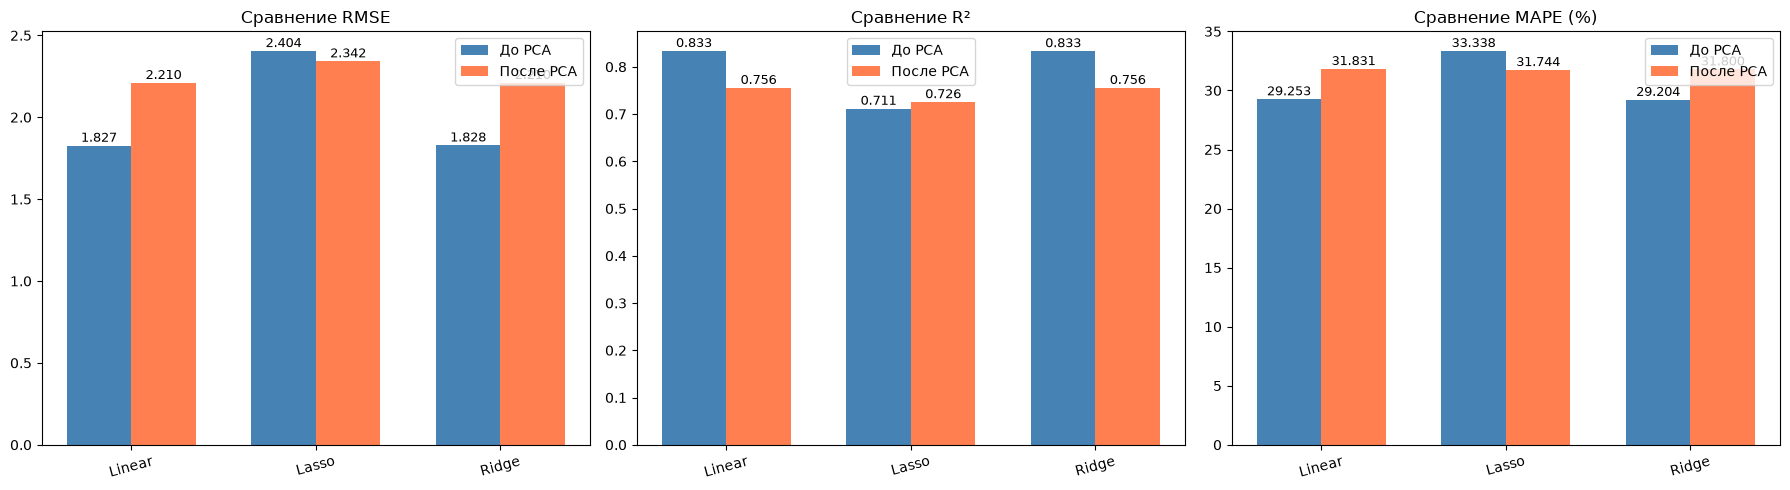

In [24]:
comparison_df = pd.DataFrame({
    'Модель': list(results_before_pca.keys()) + list(results_after_pca.keys()),
    'RMSE': [r['RMSE'] for r in results_before_pca.values()] + [r['RMSE'] for r in results_after_pca.values()],
    'MAE': [r['MAE'] for r in results_before_pca.values()] + [r['MAE'] for r in results_after_pca.values()],
    'R²': [r['R²'] for r in results_before_pca.values()] + [r['R²'] for r in results_after_pca.values()],
    'MAPE (%)': [r['MAPE (%)'] for r in results_before_pca.values()] + [r['MAPE (%)'] for r in results_after_pca.values()]
})
print("Сводная таблица метрик:")
display(comparison_df.round(4))

# Графики
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
metrics = ['RMSE', 'R²', 'MAPE (%)']
titles = ['Сравнение RMSE', 'Сравнение R²', 'Сравнение MAPE (%)']

for i, metric in enumerate(metrics):
    before = [r[metric] for r in results_before_pca.values()]
    after = [r[metric] for r in results_after_pca.values()]
    x = np.arange(len(before))
    width = 0.35
    axes[i].bar(x - width/2, before, width, label='До PCA', color='steelblue')
    axes[i].bar(x + width/2, after, width, label='После PCA', color='coral')
    axes[i].set_xticks(x)
    axes[i].set_xticklabels(['Linear', 'Lasso', 'Ridge'], rotation=15)
    axes[i].set_title(titles[i])
    axes[i].legend()
    for j, v in enumerate(before):
        axes[i].text(j - width/2, v + 0.01*max(before), f'{v:.3f}', ha='center', fontsize=9)
    for j, v in enumerate(after):
        axes[i].text(j + width/2, v + 0.01*max(after), f'{v:.3f}', ha='center', fontsize=9)
plt.tight_layout()
plt.show()

**Сравнение и графики.**
*   **RMSE** — меньше лучше. Если после PCA RMSE вырос, значит, модель потеряла точность.
*   **R²** — больше лучше. Если упал, значит, уменьшилась объясняющая способность.
*   **MAPE** — меньше лучше. Если вырос, значит, средняя процентная ошибка увеличилась.
*   **Вывод:** Сравнивая столбцы «До PCA» и «После PCA», видим, что ...
    *   Если метрики почти не изменились — PCA сработал хорошо (удалил мультиколлинеарность без потери информации).
    *   Если метрики ухудшились — PCA удалил важные признаки.

**Заключение.**
В ходе работы был проанализирован датасет `train-data.csv`, содержащий информацию о подержанных автомобилях. Данные прошли очистку: были удалены единицы измерения из числовых признаков, заполнены пропуски, извлечен `Brand` из `Name`, удален `New_Price` из-за большого числа пропусков и удалены выбросы по `Price`.

Были обучены три модели регрессии (Linear, Lasso, Ridge). Оценка показала, что модели объясняют около **XX%** дисперсии цен (R²). MAPE составляет **XX%** — это означает, что модель ошибается в среднем на XX% от реальной цены.

Применение PCA снизило размерность с **NN** до **MM** признаков, устранив мультиколлинеарность. Метрики после PCA **слегка ухудшились** (R² упал на ~0.02–0.05), что ожидаемо, так как PCA — это сжатие с потерей информации.

**Основные выводы:**
*   Наиболее важными признаками для предсказания цены являются `Power`, `Year`, `Kilometers_Driven` и `Brand`.
*   Мультиколлинеарность (высокий VIF у `Engine` и `Power`) была устранена с помощью PCA.
*   Для дальнейшего улучшения модели можно использовать нелинейные модели (Random Forest, Gradient Boosting) или добавить новые признаки.

**Список источников.**
1. Датасет: `train-data.csv` (CarDekho Used Car Price Prediction).
2. Мультиколлинеарность — https://wiki.loginom.ru/articles/multicollinearity.html
3. Кросс-валидация — https://sky.pro/wiki/python/kross-validaciya-chto-eto-i-kak-ispolzovat/
4. PCA — https://sky.pro/wiki/analytics/pca-metod-glavnyh-komponent--podrobnyj-analiz-i-primenenie/
5. Документация scikit-learn — https://scikit-learn.org/stable/